# Fresh-pair weighted score versus actual matching accuracy

The default experiment uses **3 fresh pairs per setting**, **1,000 distinct uniformly random seed sets per pair**, and **one matching run per set**: **27,000 runs** across Percolation, GOAT and FAQ on ER, PAPER and Chung–Lu.

All graphs have 600 vertices and the original training parameters. Budgets are Percolation 8/7/5, GOAT 15/12/9 and FAQ 29/29/27 (ER/PAPER/Chung–Lu). Pairs come from a separate seed stream and exclude the original fixed pairs, pooled training pairs, round-1 pairs and completed score-transfer grid pairs. GOAT and FAQ share graph pairs, as in training.

The nine pooled four-feature logistic models stay frozen. Each pair's random sets provide feature means and sample SDs; this normalization uses no matching outcomes. Every set is evaluated, regardless of score. FAQ is run once, matching the collection protocol. Allow roughly 5–7 hours with three workers and no competing matching jobs.

The x-axis is the **frozen weighted score**, not a probability or predicted matching accuracy:

$$s(S)=\sum_{f \in \{\mathrm{degree,harmonic,pair\ mass,uniqueness}\}} w_f\,z_f(S),\qquad z_f(S)=\frac{f(S)-\mu_f}{\sigma_f}.$$

The weights $w_f$ were fitted earlier and are never refitted here. Each pair's **original 1,000 random sets** provide $\mu_f$ and the sample SD $\sigma_f$. Degree here means seed-to-nonseed edges divided by the number of seeds; harmonic is mean seed harmonic centrality; pair mass measures shared seed neighbours of non-seeds; uniqueness is the fraction of non-seeds with a unique capped-distance fingerprint.

The random sets' score is centered at zero. The score's own SD need not be one, so a cloud mostly between −1.5 and 1.5 is normal. Zero means the weighted random-set average, not a 50% success probability. Scores are not bounded: constructed sets may fall well beyond that range. Coefficients and reference distributions differ between settings, so score magnitudes are mainly for comparisons within a pair. The logistic intercept is not included, and these scores should not be read as calibrated probabilities.

The y-axis is **actual unseeded accuracy**. Two horizontal blobs are expected when the matcher either recovers almost everything or fails. A useful score can change the chance of reaching the upper blob without producing a linear diagonal cloud. These plots contain points only, with no binned orange lines.


In [1]:
from pathlib import Path
import sys
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'selection_rule_comparison':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
from selection_rule_comparison import fresh_pair_scores as F
F = importlib.reload(F)
from selection_rule_comparison import fresh_pair_extremes as E
E = importlib.reload(E)

ALGORITHMS = F.ALGORITHMS
MODELS = F.MODELS
N_PAIRS = 3
SETS_PER_PAIR = 1000
JOBS = 3
BLAS_THREADS = 3
RUN_SELECTED = True   # earlier pool tails and rule anchors; completed rows are reused
RUN_METRICS = True    # wider metric-based construction; completed rows are reused
print('Results:', F.OUTPUT_DIR)
display(F.status(ALGORITHMS, MODELS, N_PAIRS))


Results: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/fresh_pair_scores


,algorithm,model,complete_pairs,sets
0,percolation,sparse_er,3,3000
1,percolation,paper_pa,3,3000
2,percolation,chung_lu,3,3000
3,goat,sparse_er,3,3000
4,goat,paper_pa,3,3000
5,goat,chung_lu,3,3000
6,faq,sparse_er,3,3000
7,faq,paper_pa,3,3000
8,faq,chung_lu,3,3000


## Collect or resume

Run the next cell to start. Interrupting stops the workers; rerunning keeps every completed row. Keep the design and thread count unchanged when resuming. To try a different design, set `FRESH_PAIR_SCORES_OUTPUT_DIR` before importing the module, or use a separate terminal with that environment variable.

Stop the SBM collection in its terminal before starting this run if it is still running. It can resume tomorrow with its original command.


In [2]:
completed = F.run_all(algorithms=ALGORITHMS, models=MODELS, n_pairs=N_PAIRS,
                      sets_per_pair=SETS_PER_PAIR, jobs=JOBS, blas_threads=BLAS_THREADS)
display(F.status(ALGORITHMS, MODELS, N_PAIRS))


0 pairs remaining; about 0.0 hours with 3 jobs. Saving to /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/fresh_pair_scores


,algorithm,model,complete_pairs,sets
0,percolation,sparse_er,3,3000
1,percolation,paper_pa,3,3000
2,percolation,chung_lu,3,3000
3,goat,sparse_er,3,3000
4,goat,paper_pa,3,3000
5,goat,chung_lu,3,3000
6,faq,sparse_er,3,3000
7,faq,paper_pa,3,3000
8,faq,chung_lu,3,3000


## Scatter plots: metric extremes and the score range between them

Grey points remain the original 1,000 uniform random sets. The constructed sets use the same A/B, budget, frozen weights and original normalization. Every selection uses A only.

| Group | Selection | Global top-ten guarantee? |
|---|---|---|
| Purple triangles: total vertex degree | Ten size-k sets with largest mean total vertex degree | Yes; additive vertex weights |
| Blue pluses: harmonic | Ten sets with largest mean seed harmonic centrality | Yes; additive vertex weights |
| Pink diamonds: cut degree | Ten best found for seed-to-nonseed degree | No; multi-start sampled swap search |
| Red squares: pair mass | Ten best found for shared-neighbour pair mass | No; multi-start sampled swap search |
| Cyan crosses: uniqueness | Ten best found for capped-fingerprint uniqueness (cap 3; FAQ cap 2) | No general guarantee |
| Yellow triangles: coverage | Ten best found for non-seeds with at least one seed neighbour | No general guarantee |
| Green stars: frozen score | Ten best found for the frozen weighted score | No; multi-start sampled swap search |
| Brown circles: intermediate sets | Swap paths from a random set towards each metric's best constructed set; up to two sets from each of ten score intervals | Score-range coverage rather than optimization |

**Exact additive top ten.** Sort vertices by the metric, then use a best-first heap over ordered k-combinations. Each heap step advances a sorted index, which cannot increase the objective; popping the heap therefore produces the next globally best set. No enumeration of all $\binom{600}{k}$ sets is needed. Ties are allowed, so the ten sets can be very similar.

**Two degree definitions.** Total vertex degree is additive, whereas the score's degree feature excludes internal seed edges:

$$D_{\rm cut}(S)=\frac{\sum_{v\in S} d(v)-2e(S)}{k}.$$

The exact purple group maximizes total vertex degree. The pink group targets the actual non-additive degree feature used by the frozen score.

**Search for the non-additive metrics.** Start from the best known set for that metric, its existing rule-built set, and a random set. At each of up to eight steps, try 256 distinct random single swaps, allowing any vertex to enter. Keep an improving swap, and retain the ten highest-value distinct sets encountered, including the original random and earlier selected sets as candidates. For plotting, pool the evaluated candidates from all searches and select the ten highest-value distinct sets for each metric; objective ties favour the frozen score. A search for one metric can therefore contribute sets to another metric's plotted group. The original generating groups remain recorded in `metric_sets.csv`. This is a heuristic, not an exhaustive global or local optimality certificate. A uniqueness or coverage value of 1 does attain that metric's upper bound, although the general method remains a heuristic.

**Why intermediate sets?** Ten extreme sets can occupy nearly the same score range. The brown sets fill gaps along paths towards the extremes, so the comparison is not limited to a random cloud and a few endpoints. Uniform sampling has no intrinsic score bound, but extreme sets may be too rare to encounter in a feasible pool.

The earlier pool-tail results remain in `selected_sets.csv`; this extension writes `metric_sets.csv` and `metric_selection.json`. Identical sets reuse their saved matching outcome. Correlations and `summary.csv` still use only the original random sets. The matching runs here use the original B; the later B-redraw section retains its original 100 random sets.

Set `RUN_SELECTED = RUN_METRICS = False` to redraw saved results without collecting more. The wider extension can also run from the repository root with `python -m selection_rule_comparison.fresh_pair_extremes --jobs 3`.


Tue 22:25  [1/27] Percolation Chung-Lu pair 0: selected sets already done; about 8 min left
Tue 22:25  [2/27] Percolation ER pair 0: selected sets already done; about 8 min left
Tue 22:25  [3/27] Percolation PAPER pair 0: selected sets already done; about 8 min left
Tue 22:25  [4/27] GOAT ER pair 0: selected sets already done; about 7 min left
Tue 22:25  [5/27] GOAT PAPER pair 0: selected sets already done; about 7 min left
Tue 22:25  [6/27] GOAT Chung-Lu pair 0: selected sets already done; about 6 min left
Tue 22:25  [7/27] SGM (FAQ) ER pair 0: selected sets already done; about 6 min left
Tue 22:25  [8/27] SGM (FAQ) PAPER pair 0: selected sets already done; about 6 min left
Tue 22:25  [9/27] SGM (FAQ) Chung-Lu pair 0: selected sets already done; about 5 min left
Tue 22:25  [10/27] Percolation ER pair 1: selected sets already done; about 5 min left
Tue 22:25  [11/27] Percolation PAPER pair 1: selected sets already done; about 5 min left
Tue 22:25  [12/27] Percolation Chung-Lu pair 1: s

,algorithm,model,pair_index,budget,sets,spearman,mean_accuracy,top_fifth_accuracy,bottom_fifth_accuracy
0,faq,chung_lu,0,27,1000,0.162,0.779,0.891,0.672
1,faq,chung_lu,1,27,1000,0.229,0.606,0.737,0.470
2,faq,chung_lu,2,27,1000,0.232,0.523,0.657,0.389
3,faq,paper_pa,0,29,1000,0.221,0.596,0.729,0.468
4,faq,paper_pa,1,29,1000,0.324,0.565,0.738,0.374
5,faq,paper_pa,2,29,1000,0.275,0.425,0.549,0.288
6,faq,sparse_er,0,29,1000,0.322,0.387,0.531,0.224
7,faq,sparse_er,1,29,1000,0.262,0.456,0.617,0.338
8,faq,sparse_er,2,29,1000,0.295,0.531,0.686,0.375
9,goat,chung_lu,0,9,1000,0.079,0.737,0.787,0.672


group                  bridge  global  search
algorithm   model                            
faq         chung_lu       60      60     150
            paper_pa       60      60     150
            sparse_er      60      60     150
goat        chung_lu       54      60     150
            paper_pa       60      60     150
            sparse_er      60      60     150
percolation chung_lu       49      60     150
            paper_pa       53      60     150
            sparse_er      54      60     150

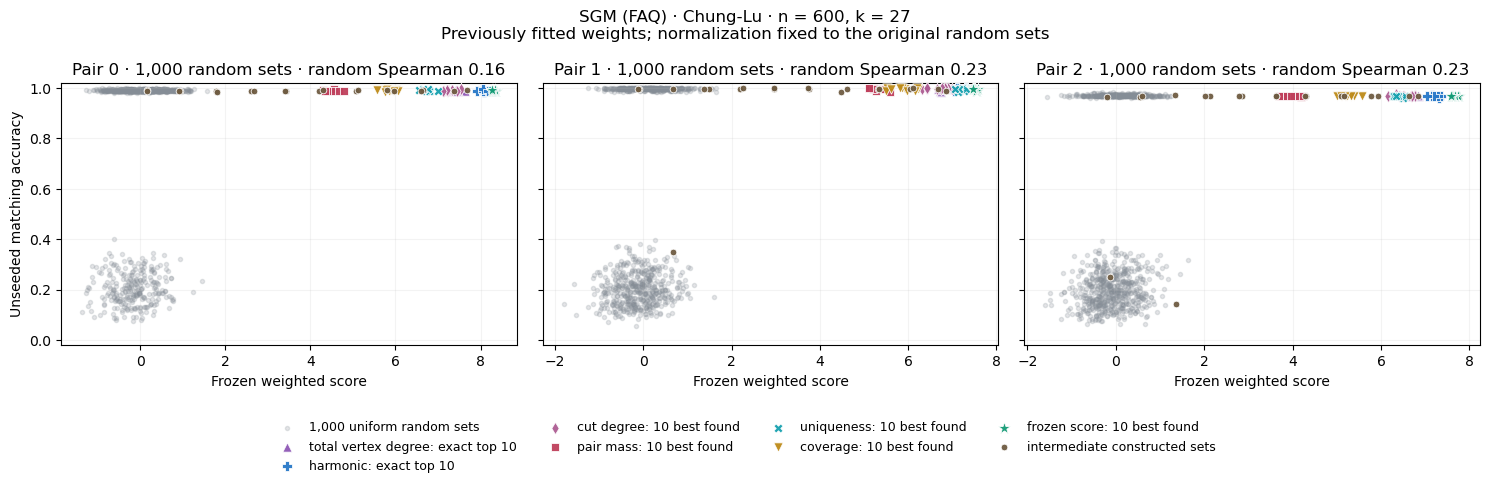

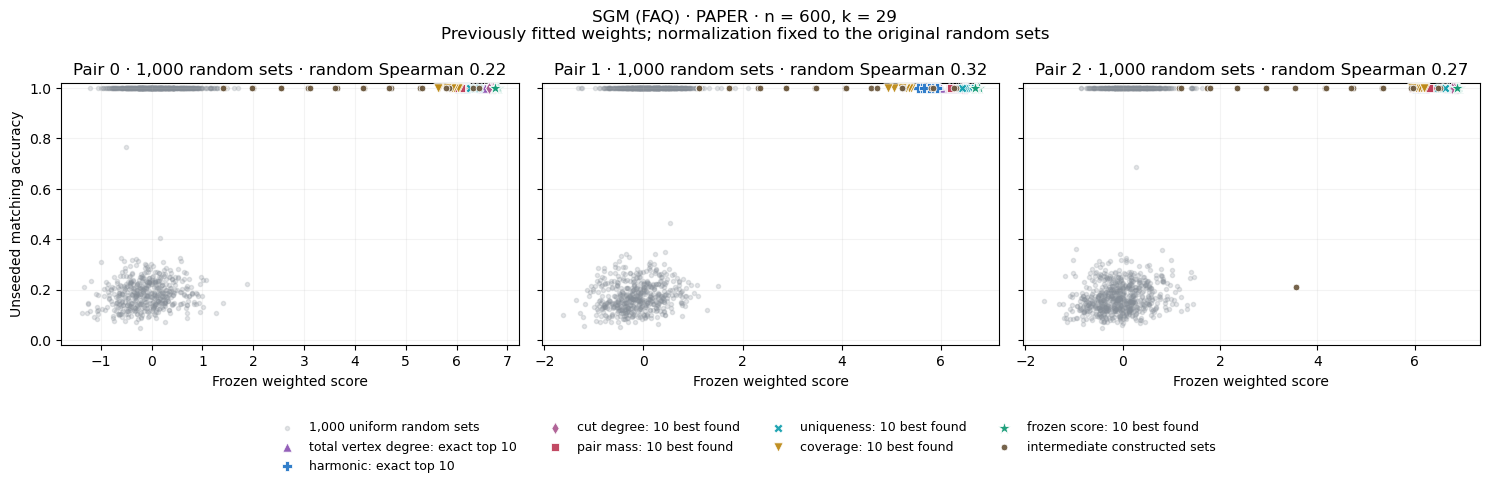

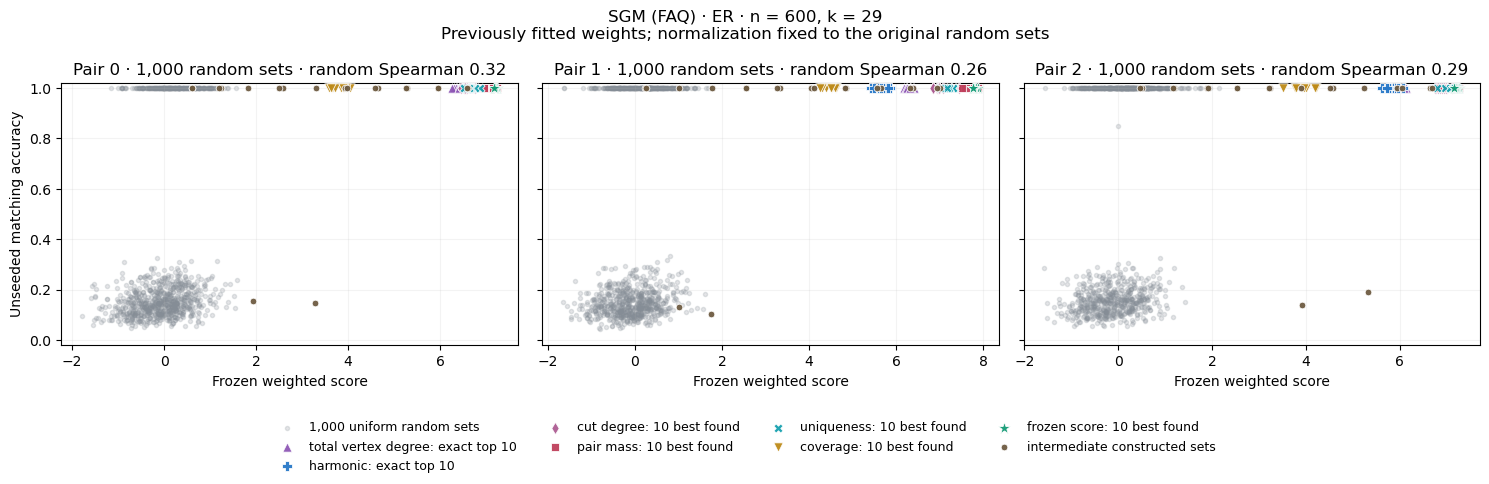

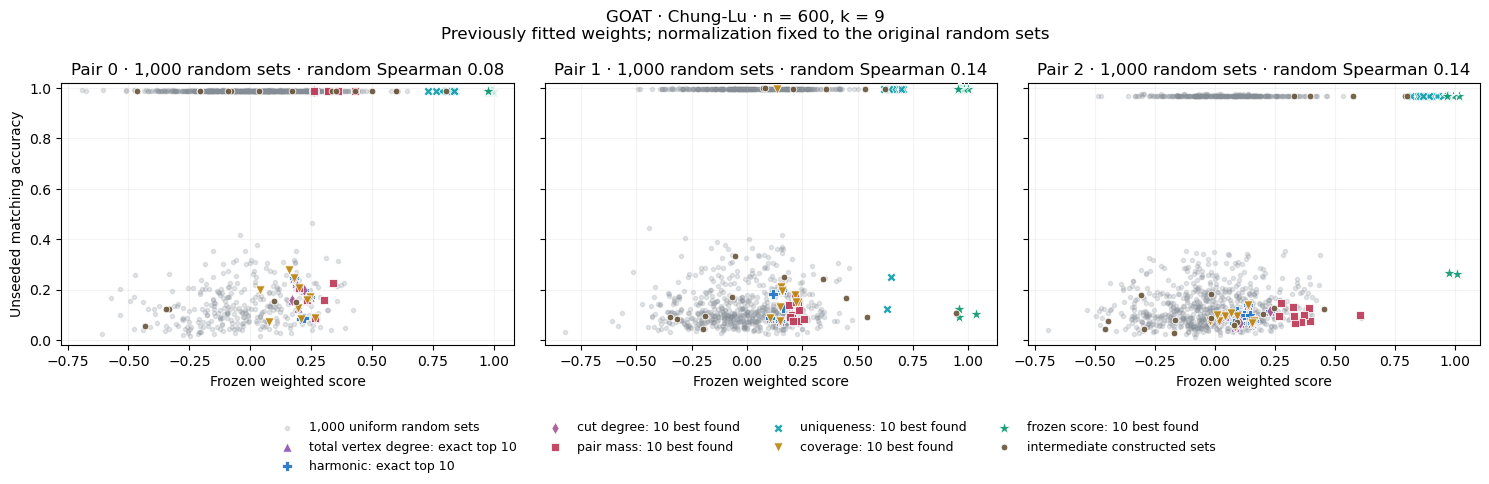

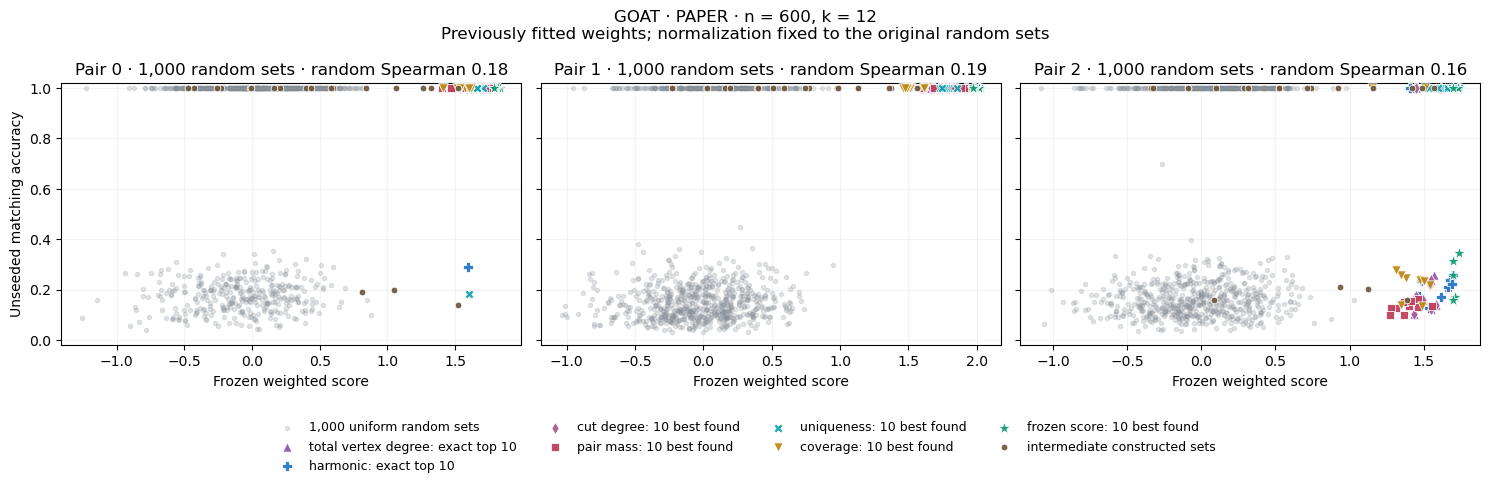

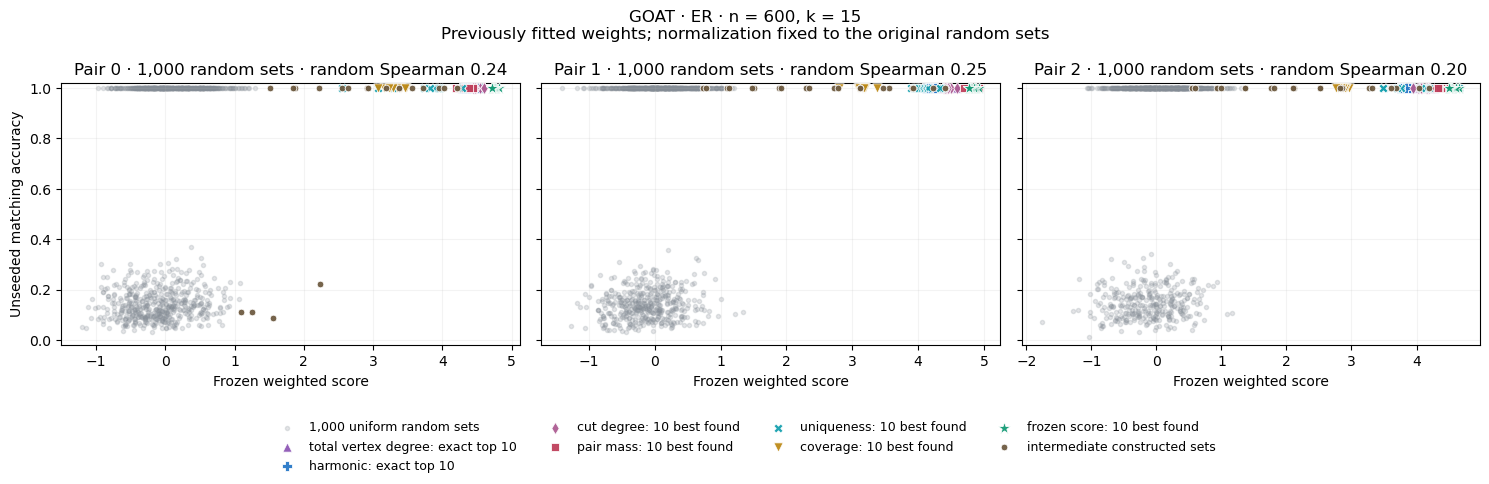

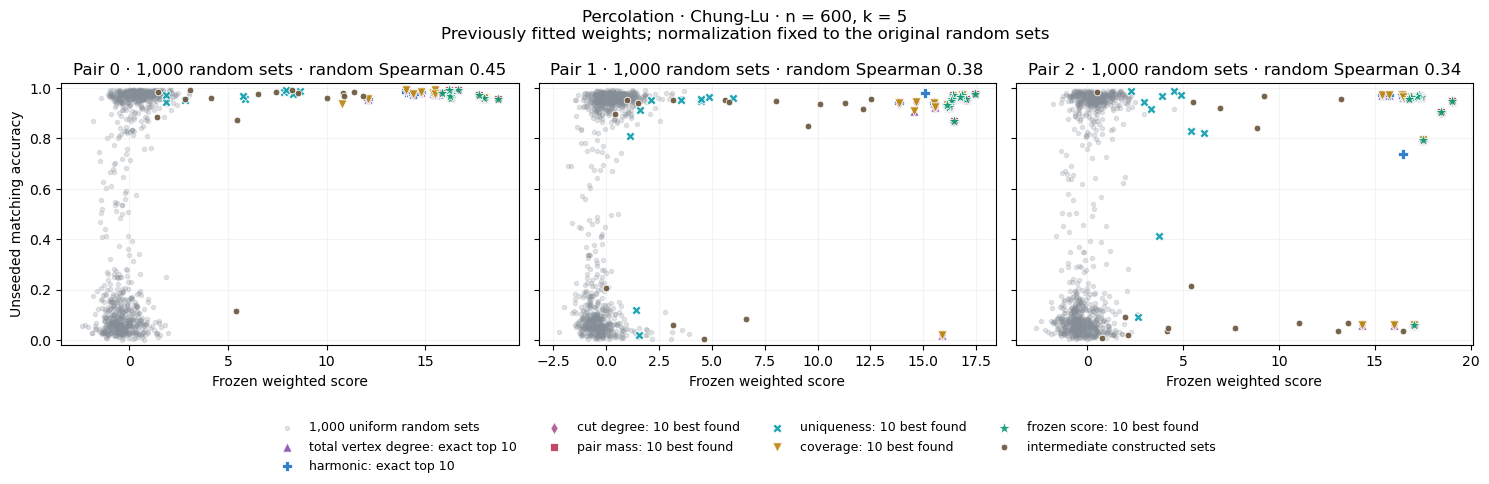

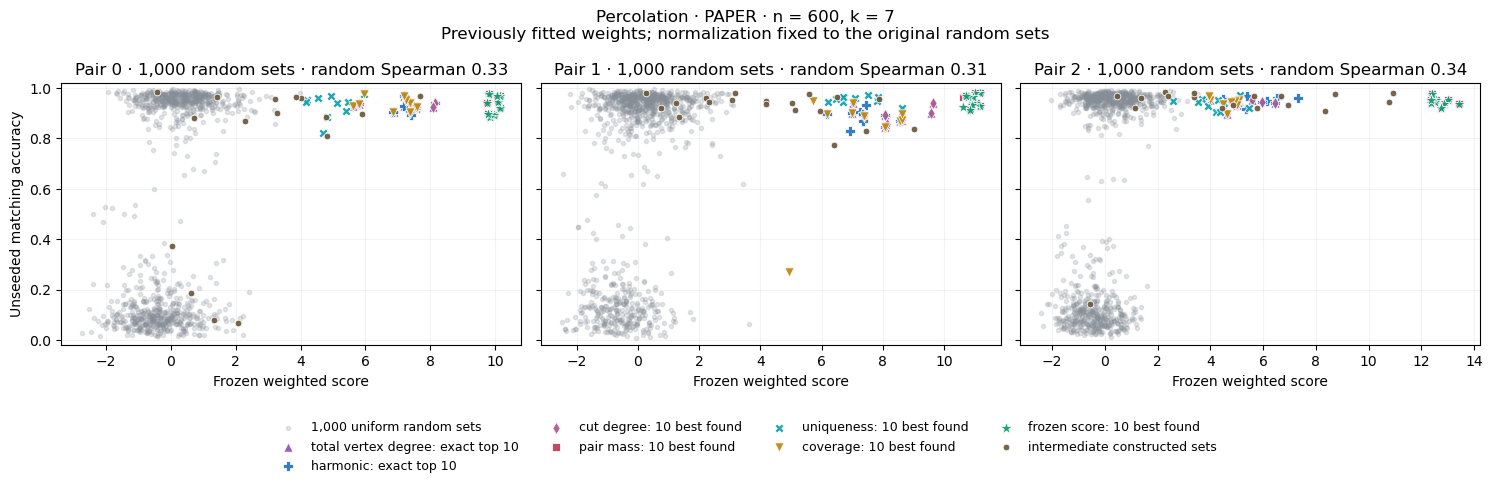

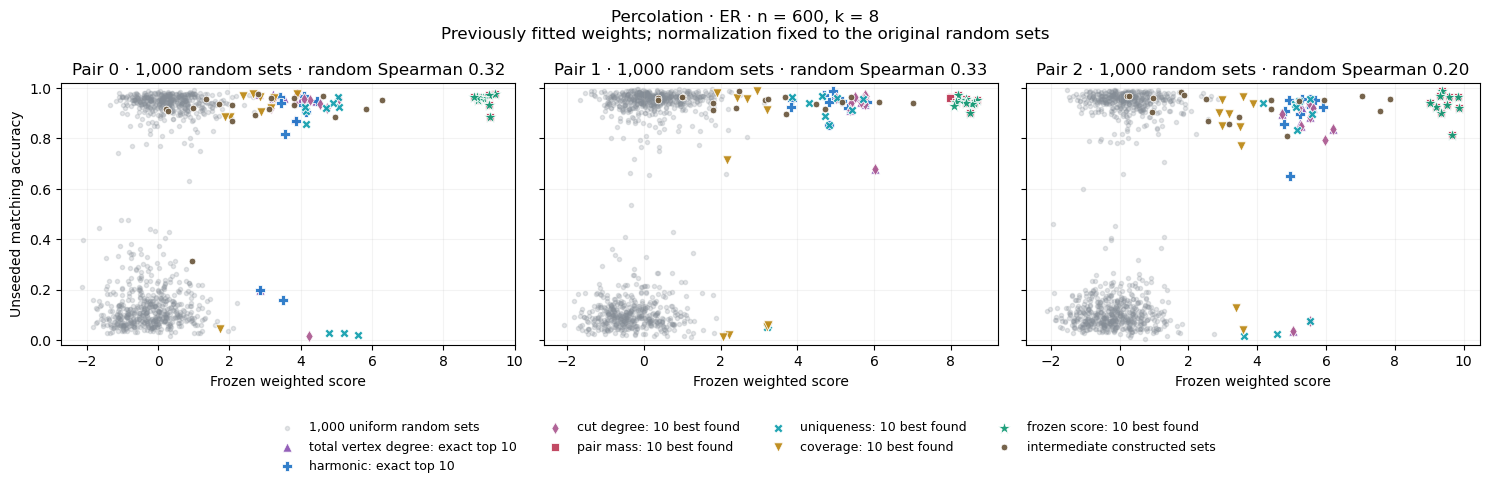

In [3]:
if RUN_SELECTED:
    F.run_selected(algorithms=ALGORITHMS, models=MODELS, n_pairs=N_PAIRS,
                   jobs=JOBS, blas_threads=BLAS_THREADS)
if RUN_METRICS:
    E.run_all(algorithms=ALGORITHMS, models=MODELS, n_pairs=N_PAIRS,
              jobs=JOBS, blas_threads=BLAS_THREADS)
data = F.read_sets()
selected = F.read_selected()
display(F.summarize(data).round(3))
if not selected.empty:
    display(selected.groupby(["algorithm", "model", "group"]).size().unstack("group", fill_value=0))
paths = F.plot_scores(data, selected=selected, save=True, show=True)
print('Saved figures:', F.OUTPUT_DIR / 'figures')


## Old fixed-pair model versus pooled model on the same external pairs

This section only reads the already completed score-transfer part A; it adds no matching runs. Old weights are refitted on each original fixed pair's 600 uniform random sets using the same four raw standardized features as the pooled model. This removes the coefficient-coordinate difference from the old degree-adjusted notebook.

Both scores are evaluated on exactly the same 60 uniform random sets on each of 20 external pairs per setting. AUC is computed within each pair and then averaged. The difference interval resamples whole test pairs (10,000 bootstrap replicates); it does not include training uncertainty. This is separate from the new dense scatter experiment. Old collection budgets can differ from pooled training budgets, so the comparison evaluates the two existing scoring approaches rather than isolating only training-pair count.


In [4]:
performance, weights = F.compare_models()
display(performance.round(3))
display(weights.pivot(index=['algorithm', 'model'], columns='feature',
                      values=['fixed_pair_weight', 'pooled_weight']).round(3))


,algorithm,model,test_pairs,test_sets,fixed_pair_auc,pooled_auc,degree_auc,auc_difference,difference_low,difference_high
0,percolation,sparse_er,20,1200,0.720,0.726,0.660,0.005,-0.007,0.017
1,percolation,paper_pa,20,1200,0.732,0.728,0.631,-0.003,-0.009,0.003
2,percolation,chung_lu,20,1200,0.737,0.739,0.663,0.002,-0.003,0.006
3,goat,sparse_er,20,1200,0.624,0.642,0.645,0.018,0.001,0.035
4,goat,paper_pa,20,1200,0.581,0.601,0.580,0.020,-0.019,0.056
5,goat,chung_lu,20,1200,0.523,0.530,0.517,0.007,-0.037,0.053
6,faq,sparse_er,20,1200,0.641,0.641,0.642,-0.000,-0.003,0.002
7,faq,paper_pa,20,1200,0.640,0.648,0.649,0.008,-0.006,0.021
8,faq,chung_lu,20,1200,0.621,0.617,0.568,-0.004,-0.016,0.007


fixed_pair_weight           ... pooled_weight           
feature                          degree harmonic  ...     pair_mass uniqueness
algorithm   model                                 ...                         
faq         chung_lu             -0.553    0.802  ...        -0.142      0.302
            paper_pa              0.384   -0.081  ...         0.014      0.098
            sparse_er             0.160    0.069  ...         0.182      0.203
goat        chung_lu             -0.030   -0.346  ...         0.032      0.090
            paper_pa              0.811   -0.581  ...         0.032      0.239
            sparse_er            -0.476    0.488  ...         0.137     -0.014
percolation chung_lu             -0.716    0.857  ...         0.551      0.057
            paper_pa             -1.001    1.357  ...         0.691     -0.005
            sparse_er            -0.013   -0.134  ...         0.575      0.103

[9 rows x 8 columns]

## Success rate over fresh draws of B

Each dot in the plots above is one run: one seed set on the one saved B. Almost every run either recovers the matching or fails, so a single 0 or 1 says little about how good a set is. Part of that luck is B itself. B is a noisy copy of A, and some draws of B may be hard to match whatever the seeds. This section keeps A and the seed sets fixed and draws B again from the same model, so each set gets a success rate.

- **Sets:** on each pair, 10 sets from each tenth of the frozen score among the 1,000 above (100 sets), with their saved scores. Nothing is refitted.
- **Draws of B:** 10 new copies of B given A, made like the original. Each edge of A stays in B at the model's edge correlation, the other vertex pairs get an edge at the matching lower rate, and PAPER's B keeps the tree it shares with A. B must be connected with no automorphisms. The saved B counts as an 11th draw.
- **Runs:** every set once on every new B, with the same solver settings and a new solver seed per run. All sets on a pair meet the same draws of B, and GOAT and FAQ share them too. This enables paired comparisons across Bs; a particular B can still favour some seed sets over others.

This is 27,000 runs (100 sets × 10 draws × 3 pairs × 9 settings), as many as the collection above: about 5–6 hours with 3 jobs, so best run overnight. Pair 0 of every setting runs first (about 2 hours). To run one algorithm only, set for example `B_ALGORITHMS = ('faq',)`; FAQ's 3 settings × 3 pairs take about 2 hours. Rerunning resumes. To run it in a terminal instead, from the repository root: `python -m selection_rule_comparison.b_replicates`, with `--algorithms faq` to limit it and `--status` to check progress. Results go to `data/fresh_pair_scores/b_replicates/`.

In [5]:
import importlib

import matplotlib.pyplot as plt

from selection_rule_comparison import b_replicates as BR
BR = importlib.reload(BR)   # picks up edits to b_replicates.py without restarting the kernel

RUN_B_REPLICATES = True
B_ALGORITHMS = BR.ALGORITHMS   # e.g. ('faq',) to run FAQ only
B_PAIRS = 3
if RUN_B_REPLICATES:
    BR.run_all(algorithms=B_ALGORITHMS, models=MODELS, n_pairs=B_PAIRS, jobs=JOBS, blas_threads=BLAS_THREADS)
display(BR.status(B_ALGORITHMS, MODELS, B_PAIRS))   # runs done per pair; 1,000 when complete

All B replicates are done. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/fresh_pair_scores/b_replicates


pair                      0     1     2
algorithm   model                      
faq         chung_lu   1000  1000  1000
            paper_pa   1000  1000  1000
            sparse_er  1000  1000  1000
goat        chung_lu   1000  1000  1000
            paper_pa   1000  1000  1000
            sparse_er  1000  1000  1000
percolation chung_lu   1000  1000  1000
            paper_pa   1000  1000  1000
            sparse_er  1000  1000  1000

### How much comes from the seed set, and how much from B?

One row per setting and pair. Only draws of B that every chosen set has finished are used.
- **success rate:** over all 100 sets and all draws.
- **original B, hardest new B, easiest new B:** the share of the 100 sets that succeed on the saved B, and on the hardest and the easiest new draw.
- **share from seed set, share from draw of B, share from the rest:** splits a single run's 0 or 1 into three parts. The seed-set part is what any score could hope to predict. The draw-of-B part is shared by all sets. The rest is solver luck plus sets that suit one draw of B but not another. Percolation's solver has no randomness, so for percolation the rest is only the set-by-draw part.
- **SD of sets' true rates:** how much the sets' success rates over many draws of B really differ, once draw-to-draw noise is removed.
- **Spearman:** the frozen score against single runs on the saved B (all 1,000 sets, then the 100 chosen sets), and against each set's success rate over all draws. The last column uses degree alone in place of the score.

In [6]:
b_runs = BR.read_runs()
display(BR.summary_table(b_runs))

budget  ...  degree: Spearman with success rate
algorithm   model    pair          ...                                    
SGM (FAQ)   Chung-Lu 0         27  ...                               0.396
                     1         27  ...                               0.549
                     2         27  ...                               0.496
            PAPER    0         29  ...                               0.517
                     1         29  ...                               0.534
                     2         29  ...                               0.543
            ER       0         29  ...                               0.587
                     1         29  ...                               0.566
                     2         29  ...                               0.423
GOAT        Chung-Lu 0          9  ...                               0.154
                     1          9  ...                               0.053
                     2          9  ...                               0.303
            PAPER    0         12  ...                               0.488
                     1         12  ...                               0.373
                     2         12  ...                               0.219
            ER       0         15  ...                               0.509
                     1         15  ...                               0.376
                     2         15  ...                               0.580
Percolation Chung-Lu 0          5  ...                               0.454
                     1          5  ...                               0.398
                     2          5  ...                               0.650
            PAPER    0          7  ...                               0.355
                     1          7  ...                               0.315
                     2          7  ...                               0.453
            ER       0          8  ...                               0.584
                     1          8  ...                               0.619
                     2          8  ...                               0.403

[27 rows x 15 columns]

### Score versus success rate

The layout matches the plots above, but y is each set's success rate over the draws of B. The top row uses the frozen score and the bottom row uses degree alone. Points only: no orange bin averages or connecting lines. These remain the 100 original score-stratified random sets per pair; the newly selected sets above have not been run over the redraws of B.


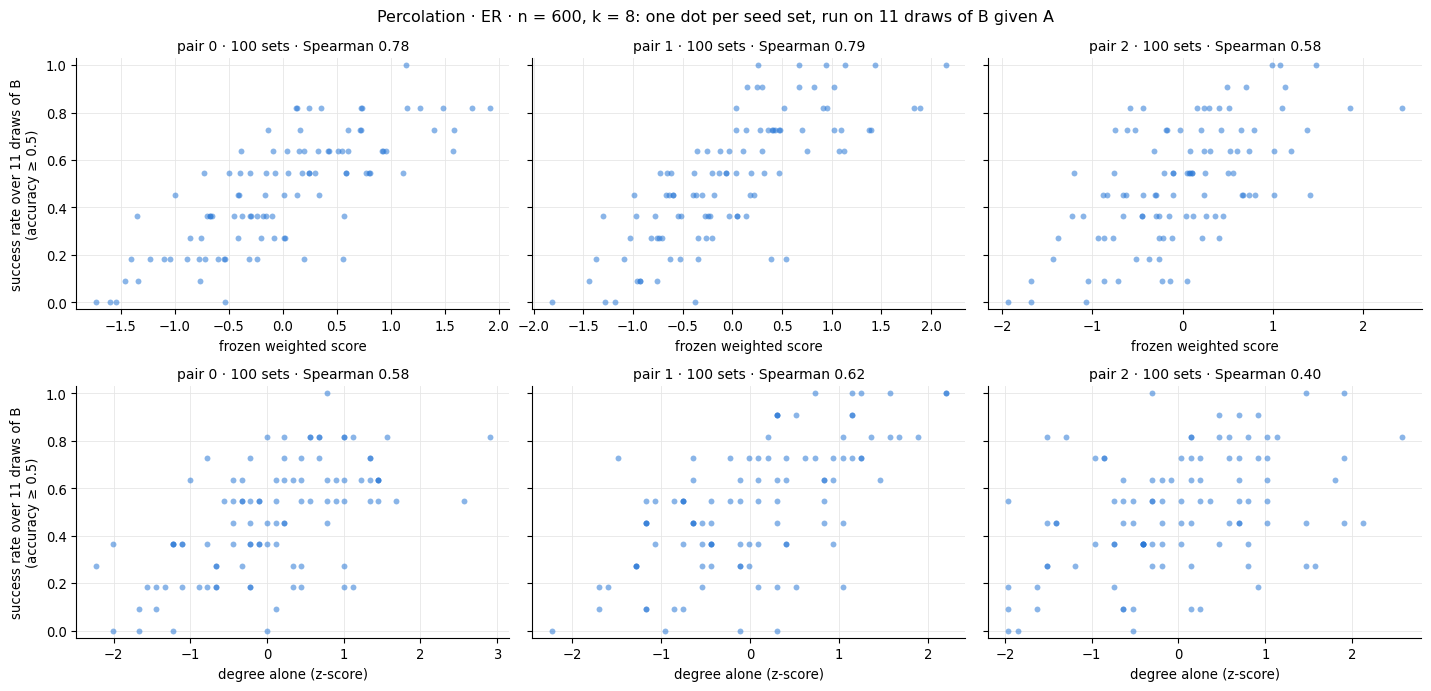

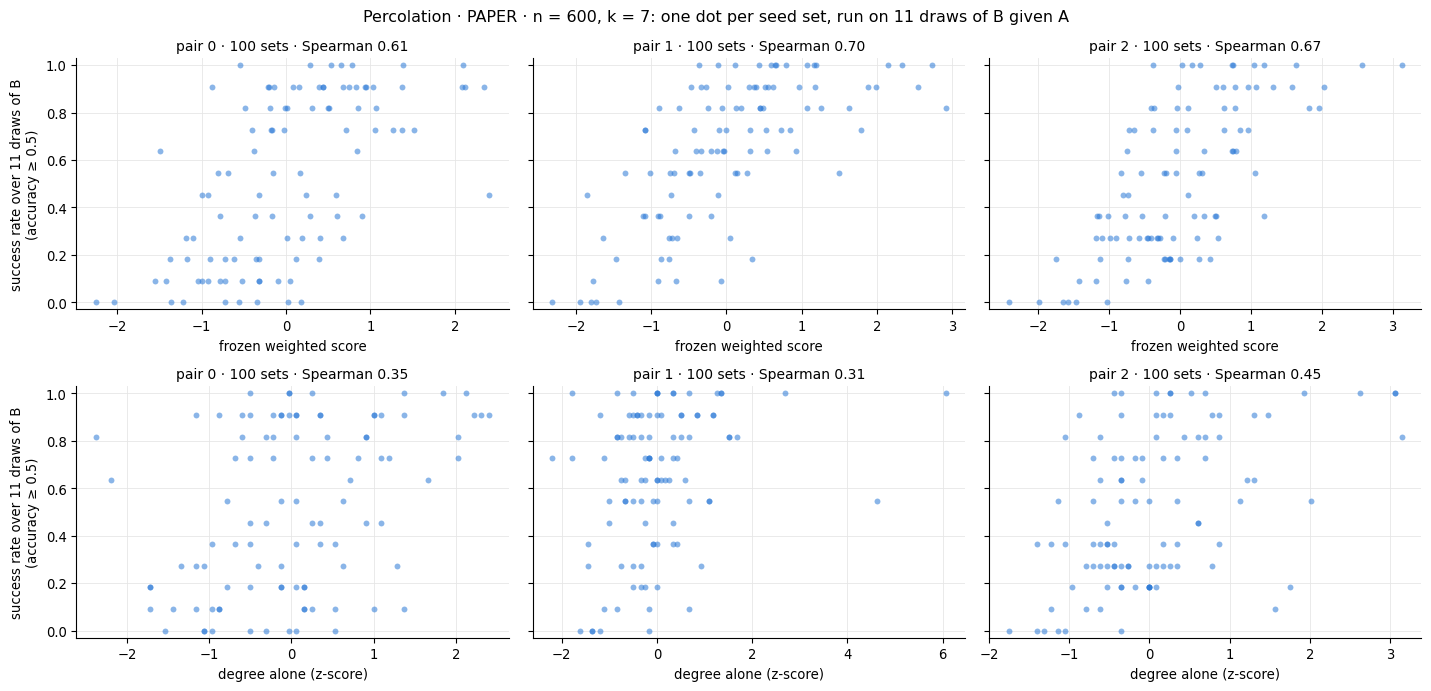

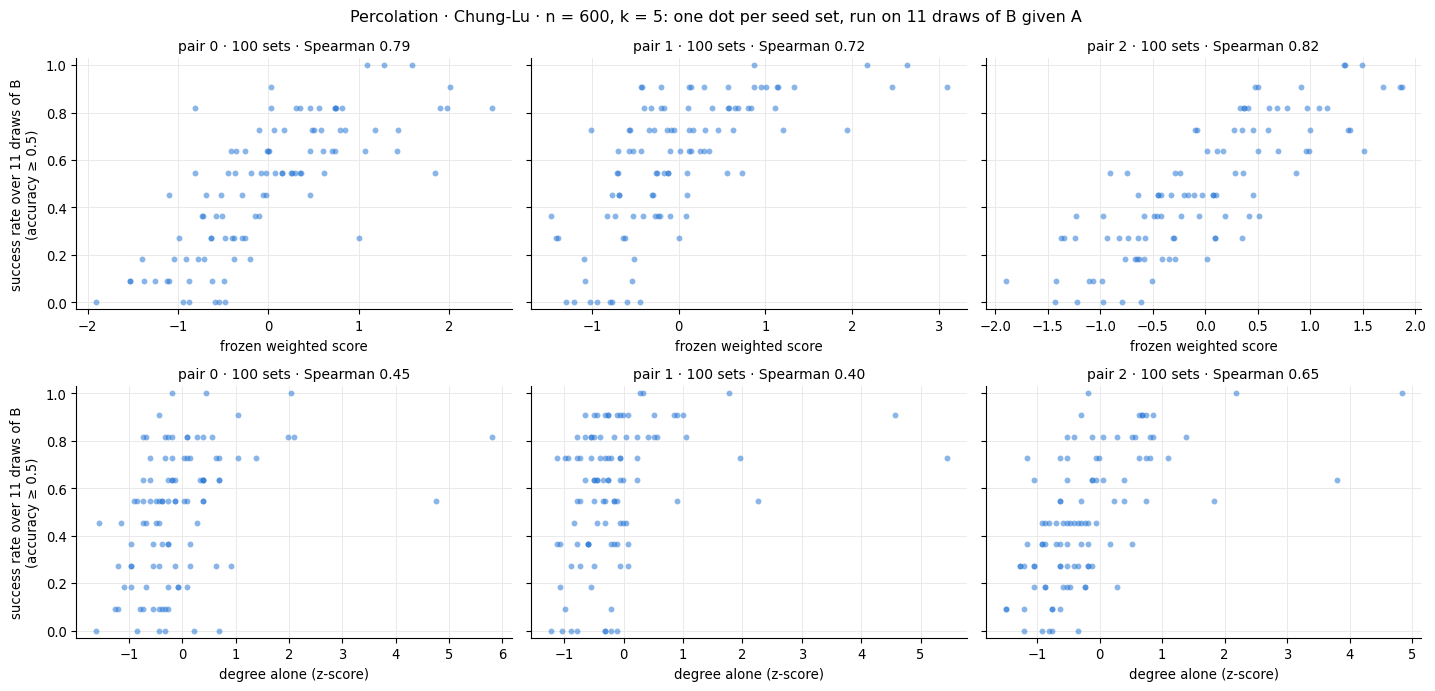

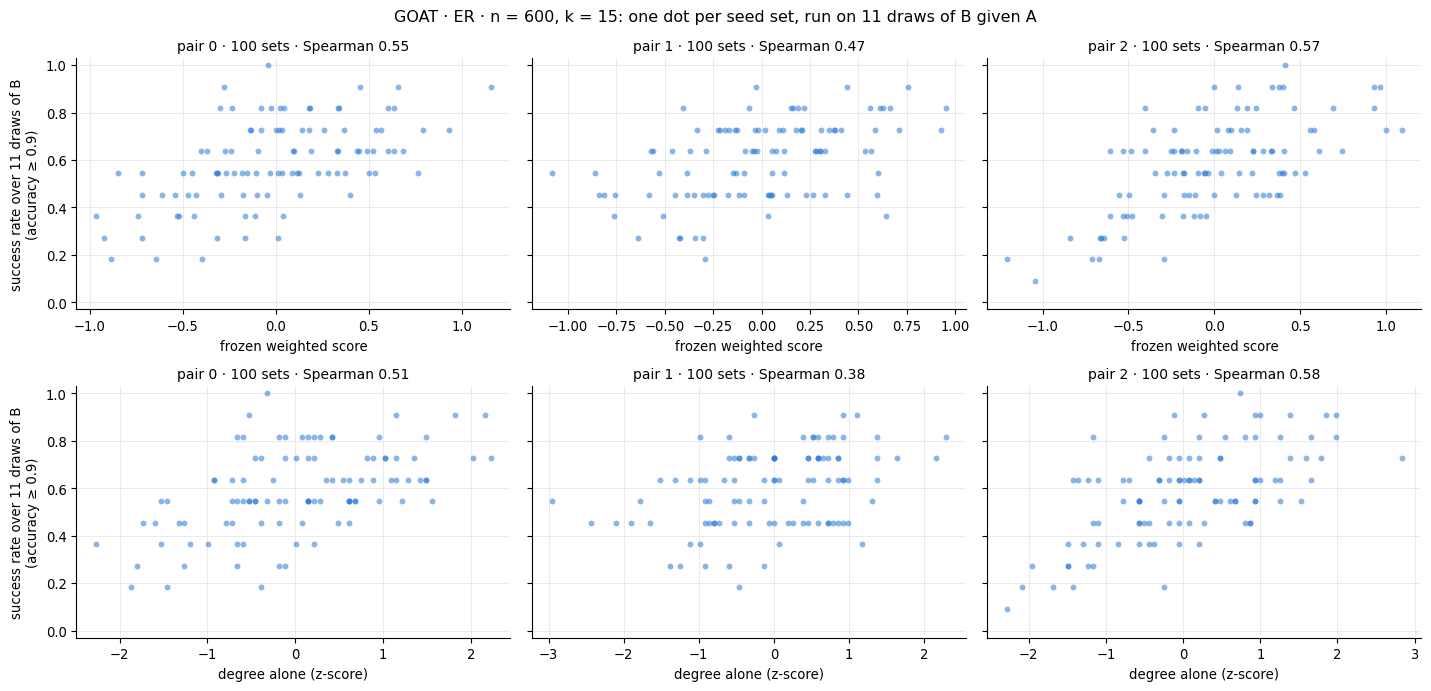

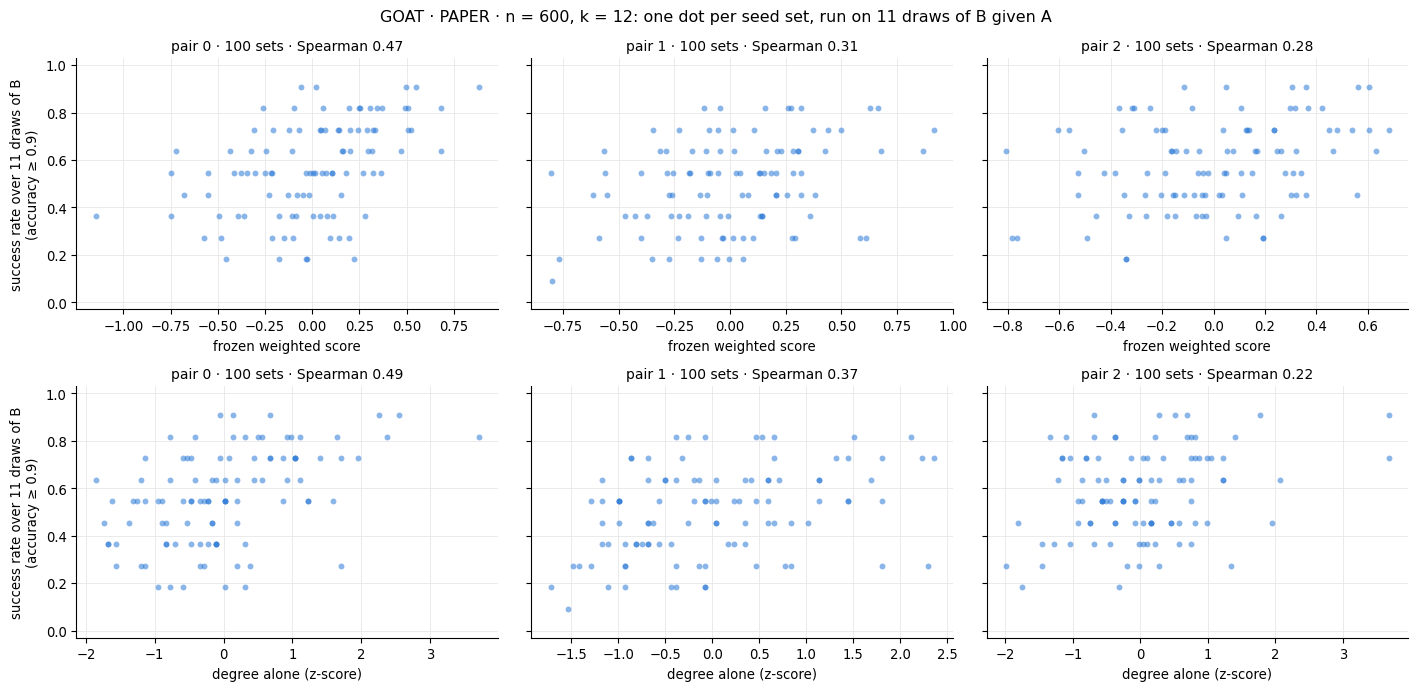

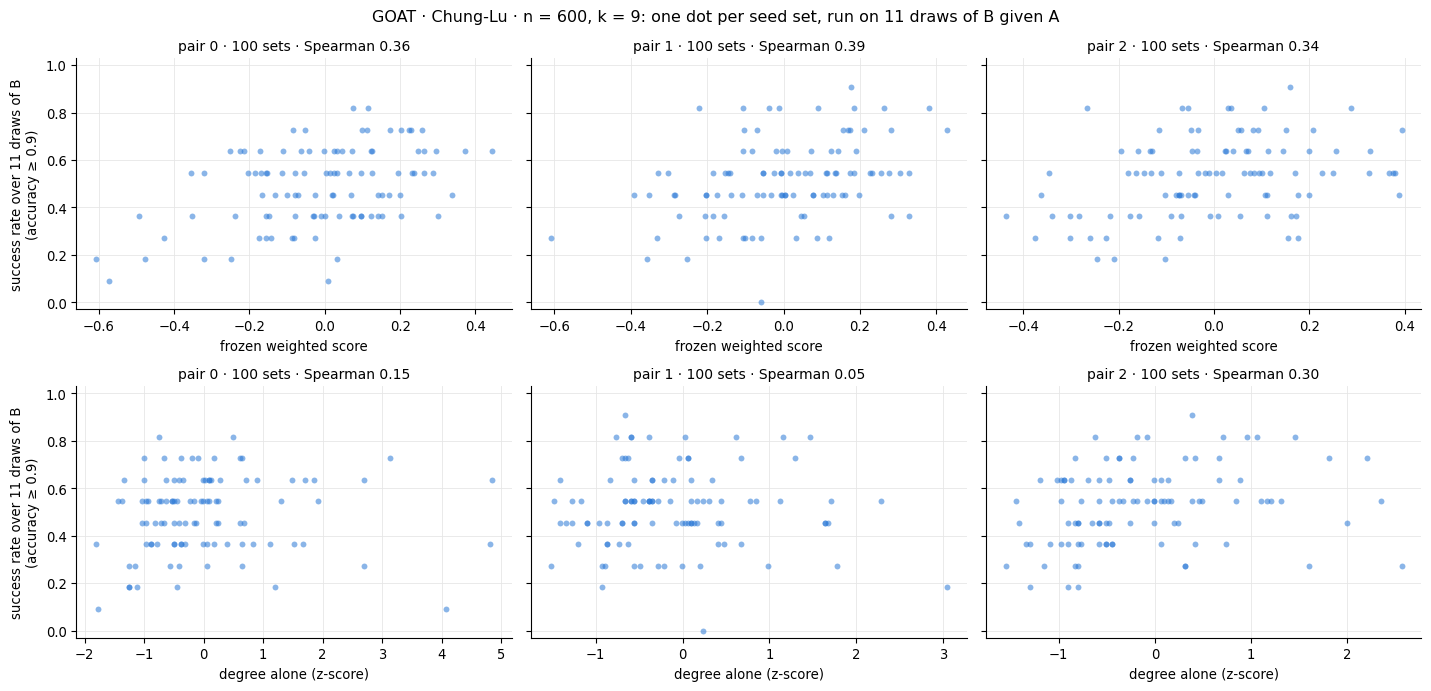

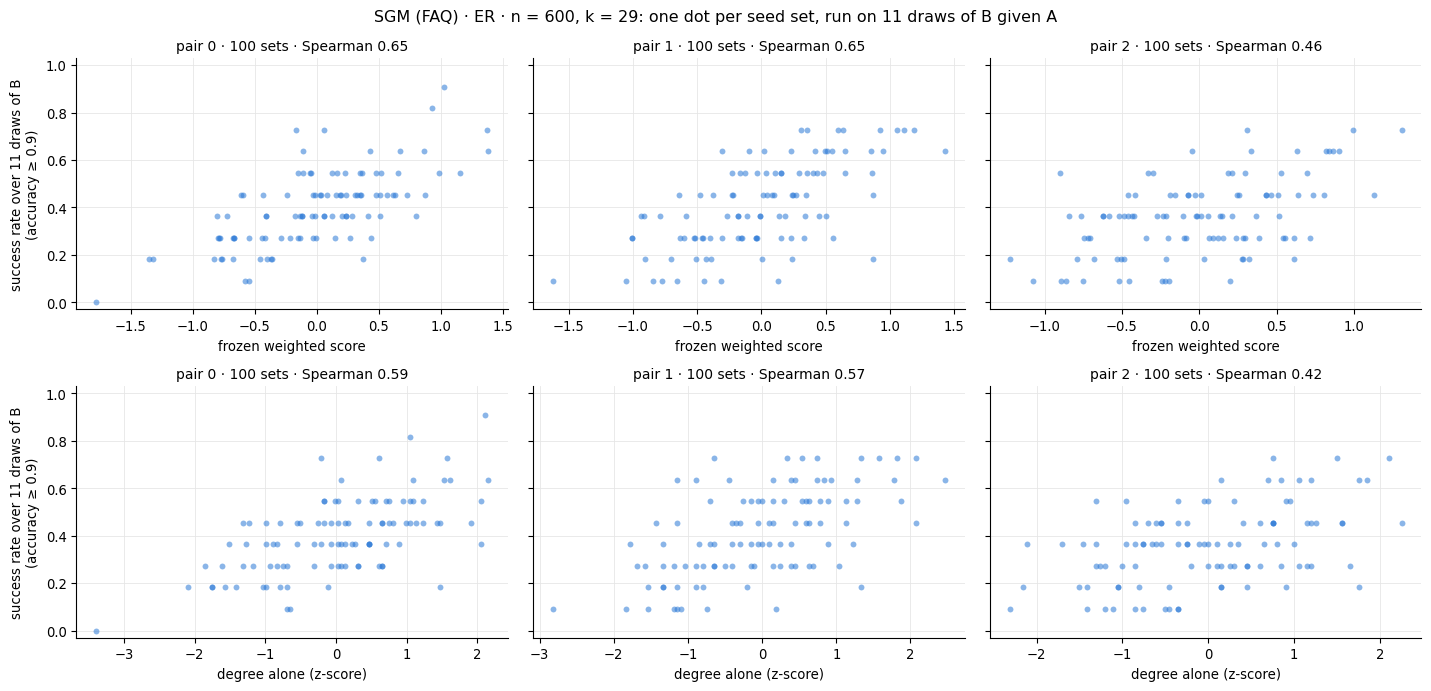

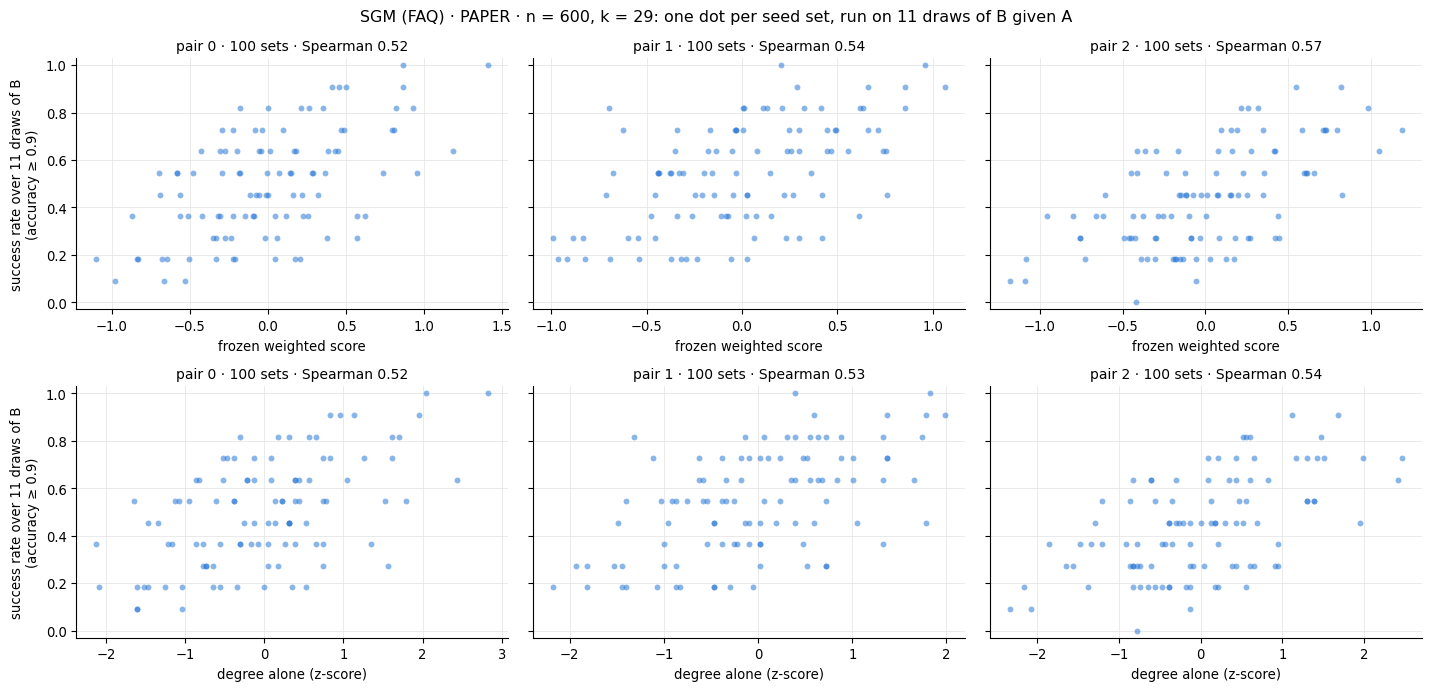

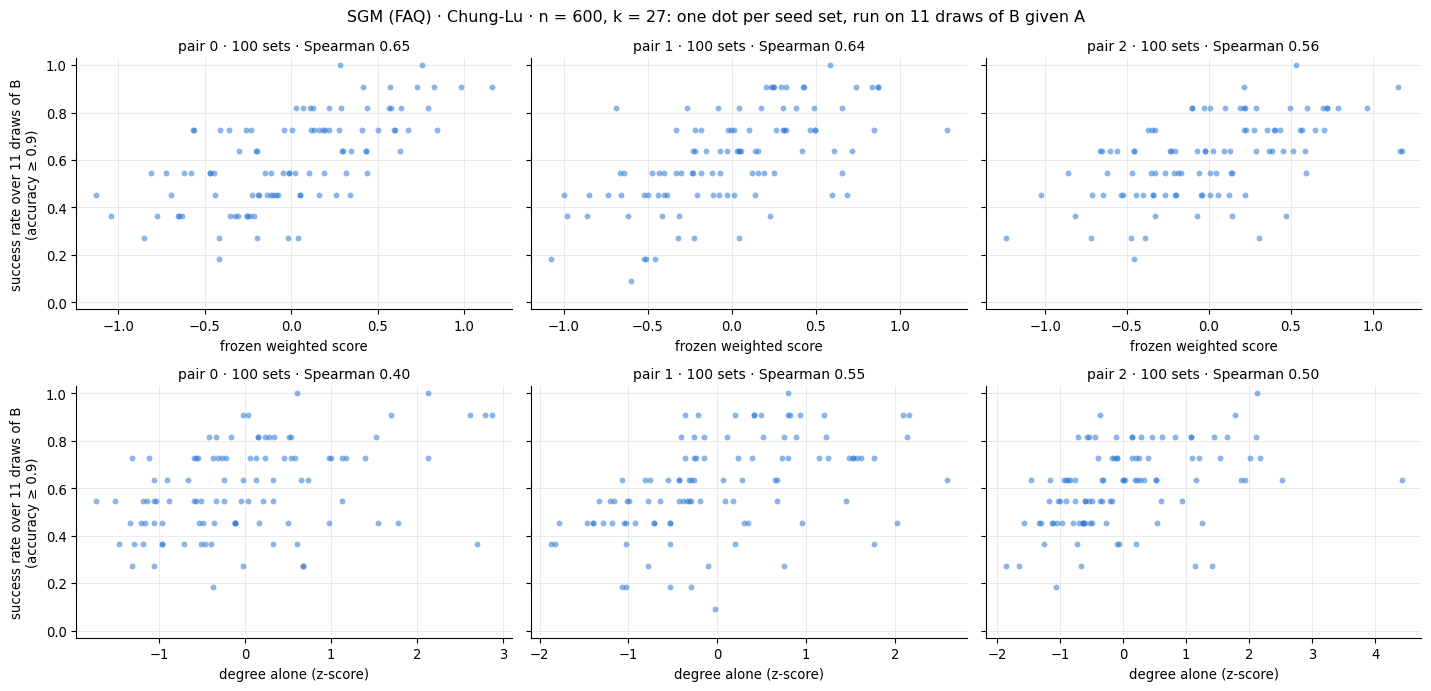

In [7]:
for algorithm, model in BR.settings_in(b_runs):
    BR.plot_rates(b_runs, algorithm, model)
    plt.show()

### Is B the coin?

Each dot is one draw of B on one pair: the share of the 100 seed sets that succeed on it. The saved B is orange. If some draws are hard for every set, the dots spread out. If they bunch together, the draw of B matters little, and the coin flips come from the solver and from how sets and draws combine.

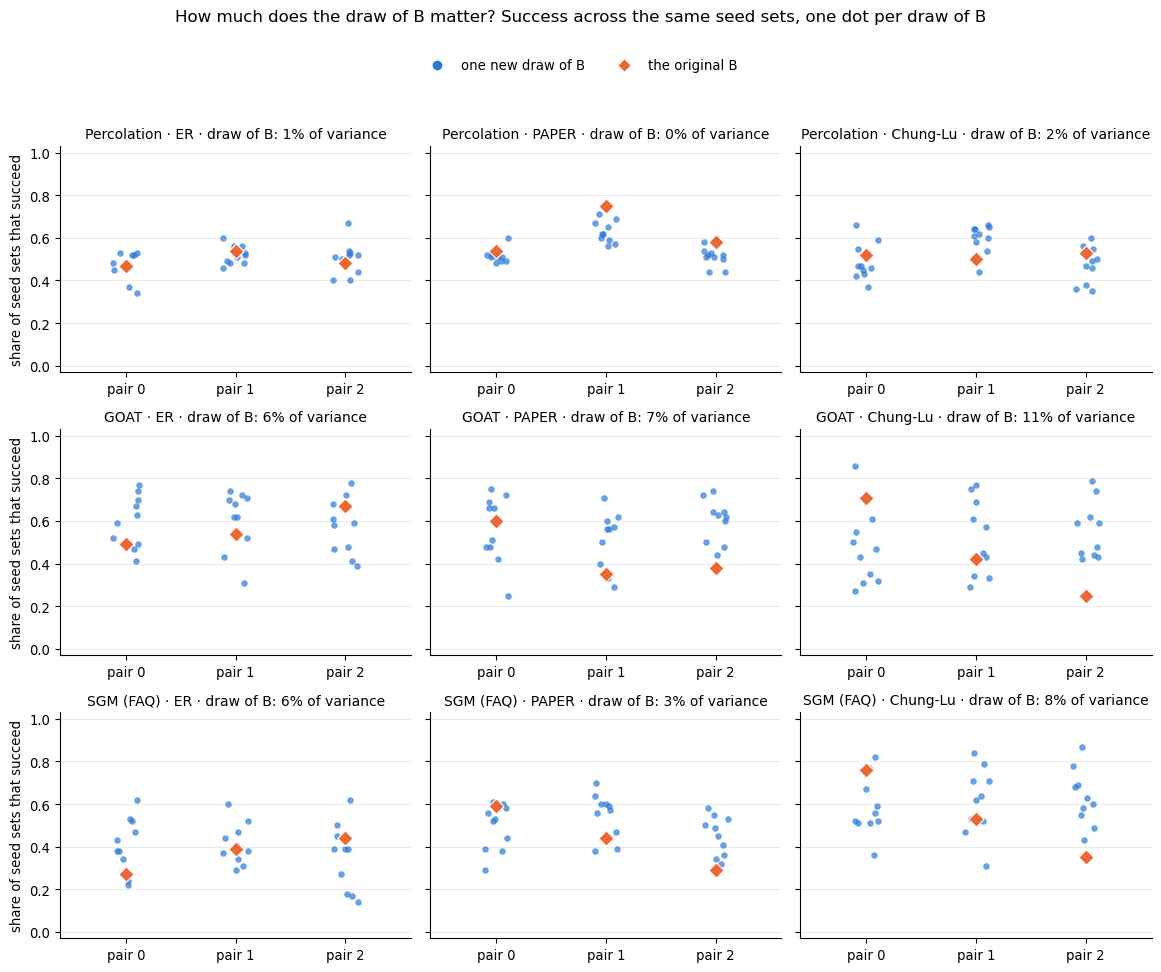

In [8]:
BR.plot_draws(b_runs)
plt.show()